In [114]:

from azure.ai.ml import MLClient
from azure.identity import DefaultAzureCredential

from azure.ai.ml.entities import Data, AmlCompute
from azure.ai.ml.constants import AssetTypes 
from azure.ai.ml import Input

import mlflow
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
from dotenv import load_dotenv
import os

load_dotenv("../.env", override=True)

subscription_id = os.environ["ARM_SUBSCRIPTION_ID"]
resource_group = os.environ["ARM_RESOURCE_GROUP"]
workspace = os.environ["AZ_ML_NAME"]
mlflow_tracking_uri = os.environ["MLFLOW_TRACKING_URI"]

ml_client = MLClient(
    DefaultAzureCredential(), subscription_id, resource_group, workspace
)

Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


### Create data assets and compute

In [46]:
# Register a training data MLTable

name = "diabetes"
version = "1"

try:
    diabetes_data = Data(
        path="../data/train/",
        type=AssetTypes.MLTABLE,
        name=name,
        version=version,
        description="diabetes training set",
    )

    res = ml_client.data.create_or_update(diabetes_data)

    print(res.id)
    print(res.path)

except Exception as e:
    if "version already exists" in str(e).lower():
        print(f"Data asset with name and version 'azureml:{name}:{version}' already exist.")
    else:
        raise e

Data asset with name and version 'azureml:diabetes:1' already exist.


In [47]:
name = "diabetes-test"
version = "1"

try: 
    diabetes_test_data = Data(
        path="../data/test/",
        type=AssetTypes.MLTABLE,
        name=name,
        version=version,
        description="diabetes test set",
    )

    res = ml_client.data.create_or_update(diabetes_test_data)

    print(res.id)
    print(res.path)
except Exception as e:
    if "version already exists" in str(e).lower():
        print(f"Data asset with name and version 'azureml:{name}:{version}' already exist.")
    else:
        raise e

Data asset with name and version 'azureml:diabetes-test:1' already exist.


In [48]:
name = "cpu-training-cluster"

try:
    cluster = AmlCompute(
        name="cpu-training-cluster",
        size="STANDARD_DS3_v2",
        min_instances=0,
        max_instances=1,
        idle_time_before_scale_down=120,   # seconds
        tier="Dedicated",                  # or "LowPriority"
    )

    ml_client.compute.begin_create_or_update(cluster).result()

except Exception as e:
    raise e


### AutoML

In [49]:
from azure.ai.ml import automl

# Register as input
training_data = Input(type=AssetTypes.MLTABLE, path="azureml:diabetes:1")

# Create an AutoML classification job
classification_job = automl.classification(
    compute="cpu-training-cluster",
    experiment_name="auto-ml-diabetes",
    training_data=training_data,
    target_column_name="Diabetic",
    primary_metric="accuracy",
    n_cross_validations=5,
    enable_model_explainability=True
)

# Set time-out limits
classification_job.set_limits(
    timeout_minutes=60, 
    trial_timeout_minutes=20, 
    max_trials=5,
    enable_early_termination=True,
)

In [50]:
# Run the job
returned_job = ml_client.jobs.create_or_update(
    classification_job
)

aml_url = returned_job.studio_url
print("Monitor your job at", aml_url)

Monitor your job at https://ml.azure.com/runs/orange_floor_5dr4nx0kf6?wsid=/subscriptions/e46b15c2-60e4-419f-a352-ee019a3b0daf/resourcegroups/rg-az-ml/workspaces/mlw-az-ml&tid=d018aec4-2b2b-4c66-9939-2c96877e6bf1


In [111]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, precision_score, recall_score, \
    f1_score, RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

mlflow.set_tracking_uri(mlflow_tracking_uri)

df = pd.read_csv("../data/train/diabetes.csv", sep=",", header=0)
df_test = pd.read_csv("../data/test/diabetes-test.csv", sep=",", header=0)

df.head()

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


In [ ]:
# Preprocess
X_train = df.drop(["Diabetic","PatientID"], axis=1)
X_test = df_test.drop(["Diabetic"], axis=1)
y_train = df["Diabetic"]
y_test = df_test["Diabetic"]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [101]:
# MLFlow autologging
with mlflow.start_run():
    mlflow.autolog()

    # Create model
    model = XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
    )

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict
    preds = model.predict(X_test_scaled)

    # Evaluate
    evaluation_set = [y_test, preds]

    cr = classification_report(*evaluation_set)
    precision, recall, fscore, support = precision_recall_fscore_support(*evaluation_set)
    accuracy = accuracy_score(*evaluation_set)

print(cr)

2026/10/04 19:04:39 INFO mlflow.tracking.fluent: Autologging successfully enabled for sklearn.
2026/10/04 19:04:39 INFO mlflow.tracking.fluent: Autologging successfully enabled for xgboost.
2026/10/04 19:05:09 ERROR mlflow.xgboost: Failed to log feature importance plot. XGBoost autologging will ignore the failure and continue. Exception: 
Traceback (most recent call last):
  File "/home/dgouwy/projects/mlops-azure/.venv/lib/python3.12/site-packages/mlflow/xgboost/__init__.py", line 824, in train_impl
    log_feature_importance_plot(features, importance, imp_type)
  File "/home/dgouwy/projects/mlops-azure/.venv/lib/python3.12/site-packages/mlflow/xgboost/__init__.py", line 674, in log_feature_importance_plot
    mlflow.log_artifact(filepath)
  File "/home/dgouwy/projects/mlops-azure/.venv/lib/python3.12/site-packages/mlflow/tracking/fluent.py", line 1670, in log_artifact
    MlflowClient().log_artifact(run_id, local_path, artifact_path)
  File "/home/dgouwy/projects/mlops-azure/.venv/li

🏃 View run lime_branch_hjtmvb6c at: https://westeurope.api.azureml.ms/mlflow/v2.0/subscriptions/e46b15c2-60e4-419f-a352-ee019a3b0daf/resourceGroups/rg-az-ml/providers/Microsoft.MachineLearningServices/workspaces/mlw-az-ml/#/experiments/b18999b8-8c8b-4397-9fc9-b6dedd5e36c1/runs/d0585737-3b33-495b-a84e-9221d8535db9
🧪 View experiment at: https://westeurope.api.azureml.ms/mlflow/v2.0/subscriptions/e46b15c2-60e4-419f-a352-ee019a3b0daf/resourceGroups/rg-az-ml/providers/Microsoft.MachineLearningServices/workspaces/mlw-az-ml/#/experiments/b18999b8-8c8b-4397-9fc9-b6dedd5e36c1
              precision    recall  f1-score   support

           0       0.96      0.97      0.97      3344
           1       0.94      0.93      0.93      1656

    accuracy                           0.96      5000
   macro avg       0.95      0.95      0.95      5000
weighted avg       0.96      0.96      0.96      5000



🏃 View run serene_hamster_kvzfdjxm at: https://westeurope.api.azureml.ms/mlflow/v2.0/subscriptions/e46b15c2-60e4-419f-a352-ee019a3b0daf/resourceGroups/rg-az-ml/providers/Microsoft.MachineLearningServices/workspaces/mlw-az-ml/#/experiments/b18999b8-8c8b-4397-9fc9-b6dedd5e36c1/runs/b10211eb-16c7-429b-a2a5-808c0c855aed
🧪 View experiment at: https://westeurope.api.azureml.ms/mlflow/v2.0/subscriptions/e46b15c2-60e4-419f-a352-ee019a3b0daf/resourceGroups/rg-az-ml/providers/Microsoft.MachineLearningServices/workspaces/mlw-az-ml/#/experiments/b18999b8-8c8b-4397-9fc9-b6dedd5e36c1


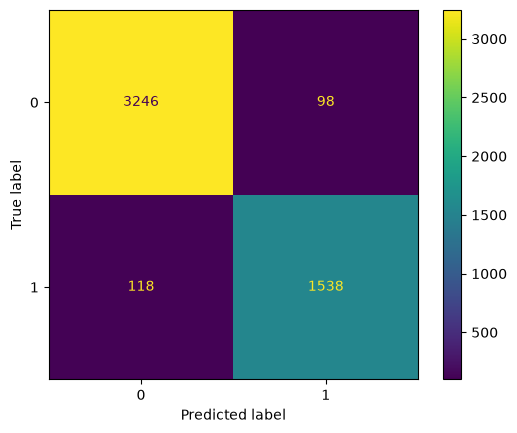

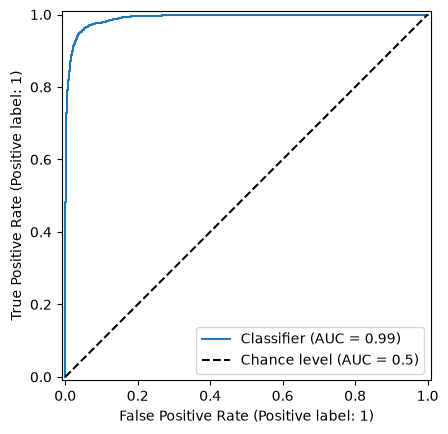

In [125]:
mlflow.autolog(disable=True)

# MLFlow custom logging
with mlflow.start_run():

    hyperparameters = {
        "n_estimators":100,
        "max_depth":5,
        "learning_rate":0.1,
        "eval_metric":"logloss"
    }

    # Create model
    model = XGBClassifier(**hyperparameters)
    mlflow.log_params(hyperparameters)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict
    preds = model.predict(X_test_scaled)
    preds_proba = model.predict_proba(X_test_scaled)[:,1]

    # Evaluate
    cr = classification_report(y_test, preds)

    # mlflow.log_text(cr, "classification_report.txt")

    cm = ConfusionMatrixDisplay.from_predictions(y_test, preds)
    roc = RocCurveDisplay.from_predictions(y_test, preds_proba, plot_chance_level=True)

    # mlflow.log_figure(roc.figure_, "plots/roc_curve.png")
    # mlflow.log_figure(cm.figure_, "plots/confusion_matrix.png")

    metrics = {
        "accuracy":accuracy_score(y_test, preds),
        "precision":precision_score(y_test, preds),
        "recall":recall_score(y_test, preds),
        "fscore":f1_score(y_test, preds),
        "AUC":roc_auc_score(y_test, preds_proba)
    }

    mlflow.log_metrics(metrics)


In [102]:
# Delete any existing computes:
ml_client.compute.begin_delete("cpu-training-cluster").result()